# 06 Full model: residual tuning on top of KG attribute prompts

The final system combines the two parts that worked:

* **Unseen side** (from `05`): KG-structured attribute prompts with learned relation-type weights and pooling temperatures.
* **Seen side** (from `04` v2): per-disease residual tuning of the classifier around the MONET text embedding.

**Unified scorer (ours).** The residual is learned on top of the prompt scorer instead of on a single text embedding:
$$z_d(x) = s^{\text{prompt}}_d(x) + \kappa\,\langle x, \Delta_d\rangle,\qquad \Delta_d = 0 \text{ for unseen diseases}$$
Unseen diseases keep their full KG attribute-prompt score; seen diseases add a learned correction. No two-branch fusion is needed; GZSL is calibrated with one offset. The v1 late-fusion variant (`fusion`) is kept as an ablation.

Epochs and the calibration offset are chosen on pseudo-unseen validation diseases, then everything is refitted on all seen diseases.

| Method | Seen side | Unseen side |
|---|---|---|
| MONET zero-shot (name) | name prompt | name prompt |
| Attribute prompts only | prompts | prompts |
| Residual + KG text (04 v2 best) | residual tuning | single KG prompt |
| Late fusion | residual tuning, fused with prompts | fused |
| **Ours (unified)** | prompts + residual | KG attribute prompts |
| Ours, shuffled KB | prompts + residual | prompts from shuffled KB |

Uses the sentence embeddings cached by `05` (`results_v2c/`). Same 10 splits. Results in `results_v2e/`, figures in `figures_v2e/`.

In [1]:
# ============ Config ============
import os
from pathlib import Path
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'

DATA = Path('data_v2'); FEAT = DATA / 'features'; KG = DATA / 'kg'
KB_CSV = Path('dermkb.csv'); MODEL_DIR = Path('models') / 'monet'
PROMPT_CACHE = Path('results_v2c')                # sentence embeddings from 05
RES, FIG = Path('results_v2e'), Path('figures_v2e')
OURS = 'Ours'

N_SPLITS, UNSEEN_FRAC, VAL_FRAC = 10, 0.20, 0.20
# prompt scorer (as in 05)
P_EPOCHS, P_LR = 20, 0.05
# residual tuning (as in 04 v2)
R_EPOCHS, R_LR, LAMBDA, LOGIT_SCALE = 30, 5e-3, 0.1, 30.0
BATCH = 512
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
METHODS = ['name', 'prompts', 'residual_kgtext', 'fusion', 'ours', 'ours_shuffled']

QUICK, FORCE = False, False
if QUICK:
    N_SPLITS, P_EPOCHS, R_EPOCHS, RES = 2, 4, 5, Path('results_v2e_quick')
for d in (RES, FIG):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
import json, math, re, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from tqdm.auto import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight', 'savefig.dpi': 300})
NAMES = {'name': 'MONET zero-shot (name)', 'prompts': 'KG attribute prompts only',
         'residual_kgtext': 'Residual tuning + KG text', 'fusion': 'Late fusion (prompts + residual)',
         'ours': OURS, 'ours_shuffled': f'{OURS}, shuffled KB'}
PAL = {'name': '#bdbdbd', 'prompts': '#a6cee3', 'residual_kgtext': '#1f78b4', 'fusion': '#6a4c93', 'ours': '#c1121f',
       'ours_shuffled': '#e9c46a'}
def savefig(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG / f'{name}.{ext}')
    print('saved', FIG / f'{name}.pdf')

if (PROMPT_CACHE / 'paired_tests.csv').exists():
    print('paired tests from 05:')
    display(pd.read_csv(PROMPT_CACHE / 'paired_tests.csv'))

paired tests from 05:


c:\Users\78479\anaconda3\envs\skin311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,comparison,metric,diff,paired_std,wins,p
0,Ours vs MONET zero-shot (name),zsl_bacc,5.73,2.15,10/10,0.0000
1,Ours vs MONET zero-shot (KG text),zsl_bacc,3.85,1.37,10/10,0.0000
2,Ours vs Description mean (no KG structure),zsl_bacc,2.29,1.21,10/10,0.0002
3,"Ours vs KG types, equal weights",zsl_bacc,1.43,0.81,9/10,0.0003
4,"Ours vs Ours, shuffled KB",zsl_bacc,1.33,0.82,10/10,0.0006
5,Ours vs MONET zero-shot (name),gzsl_h,3.99,0.75,10/10,0.0000
6,Ours vs MONET zero-shot (KG text),gzsl_h,2.83,0.77,10/10,0.0000
7,Ours vs Description mean (no KG structure),gzsl_h,1.25,0.52,10/10,0.0000
8,"Ours vs KG types, equal weights",gzsl_h,0.67,0.76,8/10,0.0222
9,"Ours vs Ours, shuffled KB",gzsl_h,0.85,0.41,10/10,0.0001


## 1. Data and prompt sentences

In [3]:
meta = pd.read_csv(DATA / 'meta.csv')
tax = pd.read_csv(DATA / 'taxonomy.csv').sort_values('disease_id').reset_index(drop=True)
Cn, y = len(tax), meta['disease_id'].to_numpy()
dname, cat_of = tax['disease'].to_numpy(), tax['category'].to_numpy()
split_lt = meta['split_lt'].to_numpy()
Xt = F.normalize(torch.from_numpy(np.load(FEAT / 'monet' / 'image.npy').astype(np.float32)), dim=-1).to(DEVICE)
T_full = F.normalize(torch.from_numpy(np.load(FEAT / 'monet' / 'text_full_text.npy').astype(np.float32)), dim=-1).to(DEVICE)
D = Xt.shape[1]
full_text = pd.read_csv(KG / 'disease_text.csv').sort_values('disease_id')['full_text'].tolist()

kb = pd.read_csv(KB_CSV).fillna('')
alias2kb = {d: d for d in kb['disease']}
for d, a in zip(kb['disease'], kb['aliases']):
    for x in [s.strip() for s in a.split(';') if s.strip()]:
        alias2kb[x] = d
kbi = kb.set_index('disease')
split_ = lambda s: [x.strip() for x in str(s).split(';') if x.strip()]

TYPES = ['name', 'full', 'primary', 'secondary', 'color', 'configuration', 'location', 'etiology', 'symptom',
         'category', 'description']
PLURAL = {'macule': 'macules', 'patch': 'patches', 'papule': 'papules', 'plaque': 'plaques', 'nodule': 'nodules',
          'tumor': 'tumors', 'cyst': 'cysts', 'vesicle': 'vesicles', 'bulla': 'bullae', 'pustule': 'pustules',
          'wheal': 'wheals', 'comedo': 'comedones', 'burrow': 'burrows', 'telangiectasia': 'telangiectasias',
          'purpura': 'purpura'}
LOC = {'generalized': 'the whole body', 'sun-exposed': 'sun-exposed skin', 'intertriginous': 'the skin folds',
       'flexural': 'the flexures', 'extensor': 'the extensor surfaces', 'periorificial': 'the skin around the orifices',
       'perioral': 'the skin around the mouth', 'upper extremities': 'the arms', 'lower extremities': 'the legs'}
ETIO = {'infectious-bacterial': 'bacterial', 'infectious-viral': 'viral', 'infectious-parasitic': 'parasitic',
        'neoplastic-benign': 'benign neoplastic', 'neoplastic-malignant': 'malignant',
        'neoplastic-premalignant': 'premalignant', 'photo-induced': 'light-induced', 'hamartoma': 'hamartomatous'}
SYMP = {'pruritus': 'itchy', 'pain': 'painful', 'tenderness': 'tender', 'burning': 'burning', 'bleeding': 'bleeding',
        'asymptomatic': 'asymptomatic'}
TEMPLATE = {
    'primary':       lambda n, v: f'a clinical photograph of {n}, which shows {PLURAL.get(v, v)}',
    'secondary':     lambda n, v: f'a clinical photograph of {n}, which shows {v}',
    'color':         lambda n, v: f'a clinical photograph of {n}, which looks {v}',
    'configuration': lambda n, v: f'a clinical photograph of {n}, with lesions in a {v} arrangement',
    'location':      lambda n, v: f'a clinical photograph of {n}, on {LOC.get(v, "the " + v)}',
    'etiology':      lambda n, v: f'a clinical photograph of {n}, a {ETIO.get(v, v)} skin condition',
    'symptom':       lambda n, v: f'a clinical photograph of {n}, which is {SYMP.get(v, v)}',
}
def build_sentences(attr_source=None):     # identical to 05, so the cached embeddings line up
    rows = []
    for i, n in enumerate(dname):
        e = kbi.loc[alias2kb[n]]
        rows.append((i, 'name', f'a clinical photograph of {n}', n))
        rows.append((i, 'full', full_text[i], ''))
        rows.append((i, 'category', f'a clinical photograph of {n}, a {cat_of[i]} skin lesion', cat_of[i]))
        src = kbi.loc[alias2kb[dname[attr_source[i]]]] if attr_source is not None else e
        for f, tmpl in TEMPLATE.items():
            for v in split_(src[f]):
                rows.append((i, f, tmpl(n, v), v))
        for s in re.split(r'(?<=[.!?])\s+', src['description']):
            if s.strip():
                rows.append((i, 'description', f'{n}: {s.strip()}', s.strip()))
    return pd.DataFrame(rows, columns=['disease_id', 'type', 'text', 'value'])

_enc = {}
@torch.no_grad()
def encode(texts, bs=128):
    from transformers import AutoModel, AutoTokenizer
    if not _enc:
        _enc['m'] = AutoModel.from_pretrained(MODEL_DIR).to(DEVICE).eval(); _enc['t'] = AutoTokenizer.from_pretrained(MODEL_DIR)
    out = []
    for i in range(0, len(texts), bs):
        t = _enc['t'](texts[i:i + bs], padding=True, truncation=True, max_length=77, return_tensors='pt').to(DEVICE)
        f = _enc['m'].get_text_features(**t); f = f if torch.is_tensor(f) else f.pooler_output
        out.append(F.normalize(f.float(), dim=-1))
    return torch.cat(out)

def embeddings(df, tag):
    f = PROMPT_CACHE / f'sent_{tag}.npy'
    if f.exists() and len(np.load(f)) == len(df):
        return torch.from_numpy(np.load(f)).to(DEVICE)
    print(f'encoding {tag} ({len(df)} sentences)')
    E = encode(df['text'].tolist()); PROMPT_CACHE.mkdir(exist_ok=True); np.save(f, E.cpu().numpy()); return E

SENT = build_sentences(); E_OWN = embeddings(SENT, 'own')
print(f'{len(meta)} images | {Cn} diseases | {len(SENT)} sentences')

16321 images | 114 diseases | 1775 sentences


## 2. Prompt scorer (from 05) and residual classifier (from 04 v2)

In [4]:
def pack(df):
    idx, msk, has = [], [], torch.zeros(Cn, len(TYPES), dtype=torch.bool)
    for r, t in enumerate(TYPES):
        g = df[df['type'] == t].groupby('disease_id').apply(lambda s: list(s.index), include_groups=False)
        K = max([len(v) for v in g] + [1])
        I = torch.zeros(Cn, K, dtype=torch.long); M = torch.zeros(Cn, K, dtype=torch.bool)
        for d, v in g.items():
            I[d, :len(v)] = torch.tensor(v); M[d, :len(v)] = True; has[d, r] = True
        idx.append(I.to(DEVICE)); msk.append(M.to(DEVICE))
    return idx, msk, has.to(DEVICE)

class Scorer(nn.Module):
    def __init__(self, E, packed, use_types, learn=True):
        super().__init__()
        self.E, (self.idx, self.msk, has) = E, packed
        on = torch.tensor([t in use_types for t in TYPES], device=DEVICE)
        self.register_buffer('m', (has & on[None, :]).float())
        self.theta = nn.Parameter(torch.zeros(len(TYPES)), requires_grad=learn)
        self.log_tau = nn.Parameter(torch.zeros(len(TYPES)), requires_grad=learn)
        self.log_scale = nn.Parameter(torch.tensor(math.log(100.0)), requires_grad=learn)
    def forward(self, x):
        S = x @ self.E.T; out = []
        for r in range(len(TYPES)):
            tau = self.log_tau[r].exp().clamp(0.01, 10.0)
            s = (S[:, self.idx[r]] / tau).masked_fill(~self.msk[r][None], float('-inf'))
            out.append(tau * (torch.logsumexp(s, -1) - torch.log(self.msk[r].sum(1).clamp(min=1).float())[None]))
        ts = torch.nan_to_num(torch.stack(out, -1), neginf=0.0)
        w = torch.softmax(self.theta, 0)[None, :] * self.m
        return self.log_scale.exp() * (ts * w[None]).sum(-1) / w.sum(-1).clamp(min=1e-8)[None]

class Residual(nn.Module):
    def __init__(self):
        super().__init__()
        self.delta = nn.Parameter(torch.zeros(Cn, D))
        self.log_scale = nn.Parameter(torch.tensor(math.log(LOGIT_SCALE)))
    def forward(self, x):
        return self.log_scale.exp().clamp(max=100) * x @ F.normalize(T_full + self.delta, dim=-1).T

class Unified(nn.Module):
    # frozen prompt scorer + learned per-disease residual (zero for diseases not trained on)
    def __init__(self, scorer):
        super().__init__()
        self.scorer = scorer
        for p in self.scorer.parameters():
            p.requires_grad_(False)
        self.delta = nn.Parameter(torch.zeros(Cn, D))
        self.log_kappa = nn.Parameter(torch.tensor(math.log(LOGIT_SCALE)))
    def forward(self, x):
        return self.scorer(x) + self.log_kappa.exp().clamp(max=100) * x @ self.delta.T

PACK_OWN = pack(SENT)
_shuf = {}
def scorer_for(kind, k):
    if kind == 'name':    return Scorer(E_OWN, PACK_OWN, ['name'], learn=False).to(DEVICE)
    if kind == 'kg_text': return Scorer(E_OWN, PACK_OWN, ['full'], learn=False).to(DEVICE)
    if kind == 'prompts': return Scorer(E_OWN, PACK_OWN, TYPES).to(DEVICE)
    if kind == 'shuffled':
        if k not in _shuf:
            df = build_sentences(np.random.default_rng(3000 + k).permutation(Cn))   # same permutation as 05
            _shuf[k] = (embeddings(df, f'shuffled_{k}'), pack(df))
        return Scorer(*_shuf[k], TYPES).to(DEVICE)

@torch.no_grad()
def predict(model, idx, bs=2048):
    idx = np.asarray(idx)
    return torch.cat([model(Xt[torch.as_tensor(idx[i:i + bs], device=DEVICE)]) for i in range(0, len(idx), bs)]).cpu()

def fit(model, tr, cls, epochs, lr, seed, reg=0.0, on_epoch=None):
    params = [p for p in model.parameters() if p.requires_grad]
    if not params or epochs == 0:
        return model
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(params, lr=lr)
    neg = torch.full((Cn,), float('-inf'), device=DEVICE); neg[torch.as_tensor(cls, device=DEVICE)] = 0
    tc = torch.as_tensor(cls, device=DEVICE); yt = torch.as_tensor(y, device=DEVICE); trt = torch.as_tensor(tr, device=DEVICE)
    for ep in range(epochs):
        for b in torch.randperm(len(tr), generator=gen).to(DEVICE).split(BATCH):
            i = trt[b]
            loss = F.cross_entropy(model(Xt[i]) + neg, yt[i])
            if reg:
                loss = loss + reg * model.delta[tc].pow(2).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        if on_epoch:
            with torch.no_grad():
                on_epoch(model, ep)
    return model

## 3. Splits and metrics (same as 04 v2 and 05)

In [5]:
def zsl_split(k):
    if k == 0:
        unseen = np.sort(meta.loc[meta['unseen'], 'disease_id'].unique())
    else:
        rng = np.random.default_rng(1000 + k); unseen = []
        for _, g in tax.groupby('category'):
            n = len(g); m = min(max(int(round(UNSEEN_FRAC * n)), 1 if n >= 3 else 0), n - 1)
            unseen += rng.choice(g['disease_id'].to_numpy(), m, replace=False).tolist()
        unseen = np.sort(unseen)
    seen = np.setdiff1d(np.arange(Cn), unseen)
    s_val = np.sort(np.random.default_rng(2000 + k).choice(seen, max(2, int(round(VAL_FRAC * len(seen)))), replace=False))
    s_tr = np.setdiff1d(seen, s_val); I = lambda c: np.where(c)[0]
    return dict(k=k, unseen=unseen, seen=seen, s_tr=s_tr, s_val=s_val,
                tr1=I(np.isin(y, s_tr) & (split_lt == 'train')), va_s=I(np.isin(y, s_tr) & (split_lt == 'val')),
                va_u=I(np.isin(y, s_val) & (split_lt != 'test')), tr2=I(np.isin(y, seen) & (split_lt == 'train')),
                te_s=I(np.isin(y, seen) & (split_lt == 'test')), te_u=I(np.isin(y, unseen)))
SPLITS = [zsl_split(k) for k in range(N_SPLITS)]

def bacc(p, t):
    return float(np.mean([(p[t == c] == c).mean() for c in np.unique(t)])) if len(t) else float('nan')
def combine(Lr, Lp, cls, a):
    c = torch.as_tensor(np.asarray(cls))
    if Lr is None:
        return torch.log_softmax(Lp[:, c], 1)
    return (1 - a) * torch.log_softmax(Lr[:, c], 1) + a * torch.log_softmax(Lp[:, c], 1)
def gzsl(G, yt, seen_pos, g):
    G = G.clone(); G[:, torch.as_tensor(seen_pos)] -= g; p = G.argmax(1).numpy(); s = np.isin(yt, seen_pos)
    a_s, a_u = bacc(p[s], yt[s]), bacc(p[~s], yt[~s])
    return a_s, a_u, (2 * a_s * a_u / (a_s + a_u) if a_s + a_u > 0 else 0.0)
def calibrate(G, yt, seen_pos):
    R = float(G.max() - G.min())
    return max(np.linspace(-R, R, 101), key=lambda g: gzsl(G, yt, seen_pos, g)[2])
def ausuc(G, yt, seen_pos):
    R = float(G.max() - G.min())
    pts = sorted({gzsl(G, yt, seen_pos, g)[:2] for g in np.linspace(-R, R, 101)}, key=lambda t: t[1])
    xs = np.array([0.0] + [p[1] for p in pts]); ys = np.array([max(p[0] for p in pts)] + [p[0] for p in pts])
    trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
    return float(trap(ys, xs)), pts

## 4. Protocol

In [6]:
SCORER = {'name': 'name', 'prompts': 'prompts', 'residual_kgtext': 'kg_text', 'fusion': 'prompts',
          'ours': 'prompts', 'ours_shuffled': 'shuffled'}
UNIFIED = ('ours', 'ours_shuffled')

def fit_scorer(kind, sp, stage, ep=None):
    k = sp['k']
    if stage == 1:
        if kind in ('name', 'kg_text'):
            return scorer_for(kind, k), 0
        best = dict(b=-1, ep=1, state=None)
        def on_epoch(m, e):
            L = predict(m, sp['va_u'])[:, torch.as_tensor(sp['s_val'])]
            b = bacc(sp['s_val'][L.argmax(1).numpy()], y[sp['va_u']])
            if b > best['b']:
                best.update(b=b, ep=e + 1, state=copy.deepcopy(m.state_dict()))
        m = fit(scorer_for(kind, k), sp['tr1'], sp['s_tr'], P_EPOCHS, P_LR, k, on_epoch=on_epoch)
        m.load_state_dict(best['state']); return m, best['ep']
    return fit(scorer_for(kind, k), sp['tr2'], sp['seen'], ep, P_LR, k), ep

def run_unified(sp, method):
    k = sp['k']
    va = np.concatenate([sp['va_s'], sp['va_u']]); allv = np.sort(np.concatenate([sp['s_tr'], sp['s_val']])); ns = len(sp['va_s'])
    # stage 1: prompt scorer, then residual on top; epoch chosen by validation H
    sc1, ep_p = fit_scorer(SCORER[method], sp, 1)
    best = dict(h=-1)
    def on_epoch(m, e):
        V = predict(m, va)
        bs = bacc(sp['s_tr'][V[:ns][:, torch.as_tensor(sp['s_tr'])].argmax(1).numpy()], y[sp['va_s']])
        bu = bacc(sp['s_val'][V[ns:][:, torch.as_tensor(sp['s_val'])].argmax(1).numpy()], y[sp['va_u']])
        h = 2 * bs * bu / (bs + bu) if bs + bu > 0 else 0
        if h > best['h']:
            best.update(h=h, ep=e + 1, state=copy.deepcopy(m.state_dict()))
    u1 = fit(Unified(sc1).to(DEVICE), sp['tr1'], sp['s_tr'], R_EPOCHS, R_LR, k, reg=LAMBDA, on_epoch=on_epoch)
    u1.load_state_dict(best['state']); ep_r = best['ep']
    G = torch.log_softmax(predict(u1, va)[:, torch.as_tensor(allv)], 1)
    gamma = calibrate(G, np.searchsorted(allv, y[va]), np.searchsorted(allv, sp['s_tr']))
    # stage 2: refit both on all seen diseases
    sc2, _ = fit_scorer(SCORER[method], sp, 2, ep_p)
    u2 = fit(Unified(sc2).to(DEVICE), sp['tr2'], sp['seen'], ep_r, R_LR, k, reg=LAMBDA)
    te_g = np.concatenate([sp['te_s'], sp['te_u']]); nts = len(sp['te_s'])
    L = predict(u2, te_g); yu = y[sp['te_u']]
    pu = sp['unseen'][L[nts:][:, torch.as_tensor(sp['unseen'])].argmax(1).numpy()]
    G = torch.log_softmax(L, 1)
    s_c, u_c, h_c = gzsl(G, y[te_g], sp['seen'], gamma)
    au, curve = ausuc(G, y[te_g], sp['seen'])
    return dict(zsl_bacc=bacc(pu, yu), gzsl_s=s_c, gzsl_u=u_c, gzsl_h=h_c, ausuc=au, alpha=float('nan'),
                ep_prompt=ep_p, ep_residual=ep_r, gamma=float(gamma), curve=curve,
                per_class_unseen={int(c): float((pu[yu == c] == c).mean()) for c in sp['unseen']})

def run(sp, method):
    if method in UNIFIED:
        return run_unified(sp, method)
    k, use_res = sp['k'], method in ('residual_kgtext', 'fusion')
    # ---------- stage 1: selection on pseudo-unseen validation diseases ----------
    sc1, ep_p = fit_scorer(SCORER[method], sp, 1)
    va = np.concatenate([sp['va_s'], sp['va_u']]); allv = np.sort(np.concatenate([sp['s_tr'], sp['s_val']]))
    Pv = predict(sc1, va); ns = len(sp['va_s'])
    if use_res:
        best = dict(h=-1)
        def on_epoch(m, e):
            Rv = predict(m, va)
            for a in ALPHAS:
                bs = bacc(sp['s_tr'][combine(Rv[:ns], Pv[:ns], sp['s_tr'], a).argmax(1).numpy()], y[sp['va_s']])
                bu = bacc(sp['s_val'][combine(Rv[ns:], Pv[ns:], sp['s_val'], a).argmax(1).numpy()], y[sp['va_u']])
                h = 2 * bs * bu / (bs + bu) if bs + bu > 0 else 0
                if h > best['h']:
                    best.update(h=h, ep=e + 1, a=a, state=copy.deepcopy(m.state_dict()))
        r1 = fit(Residual().to(DEVICE), sp['tr1'], sp['s_tr'], R_EPOCHS, R_LR, k, reg=LAMBDA, on_epoch=on_epoch)
        r1.load_state_dict(best['state']); ep_r, a = best['ep'], best['a']; Rv = predict(r1, va)
    else:
        ep_r, a, Rv = 0, 1.0, None
    G = combine(Rv, Pv, allv, a)
    gamma = calibrate(G, np.searchsorted(allv, y[va]), np.searchsorted(allv, sp['s_tr']))
    # ---------- stage 2: refit on all seen diseases, test ----------
    sc2, _ = fit_scorer(SCORER[method], sp, 2, ep_p)
    te_g = np.concatenate([sp['te_s'], sp['te_u']]); nts = len(sp['te_s'])
    Pt = predict(sc2, te_g)
    Rt = predict(fit(Residual().to(DEVICE), sp['tr2'], sp['seen'], ep_r, R_LR, k, reg=LAMBDA), te_g) if use_res else None
    allc = np.arange(Cn)
    Zu = combine(None if Rt is None else Rt[nts:], Pt[nts:], sp['unseen'], a)
    pu = sp['unseen'][Zu.argmax(1).numpy()]
    G = combine(Rt, Pt, allc, a)
    s_c, u_c, h_c = gzsl(G, y[te_g], sp['seen'], gamma)
    au, curve = ausuc(G, y[te_g], sp['seen'])
    yu = y[sp['te_u']]
    return dict(zsl_bacc=bacc(pu, yu), gzsl_s=s_c, gzsl_u=u_c, gzsl_h=h_c, ausuc=au, alpha=a, ep_prompt=ep_p,
                ep_residual=ep_r, gamma=float(gamma), curve=curve,
                per_class_unseen={int(c): float((pu[yu == c] == c).mean()) for c in sp['unseen']})

## 5. Run (resumable)

In [7]:
RUNS = RES / 'runs.jsonl'
load_runs = lambda: [json.loads(l) for l in open(RUNS)] if RUNS.exists() else []
done = set() if FORCE else {r['key'] for r in load_runs()}
for sp in tqdm(SPLITS):
    for m in METHODS:
        key = f"{m}|{sp['k']}"
        if key in done:
            continue
        t0 = time.time(); rec = run(sp, m)
        with open(RUNS, 'a') as fh:
            fh.write(json.dumps(dict(key=key, method=m, split=sp['k'], secs=round(time.time() - t0, 1), **rec)) + '\n')
        done.add(key)
print('finished runs:', len(done))

  0%|          | 0/10 [00:00<?, ?it/s]C:\Users\78479\AppData\Local\Temp\ipykernel_31576\2779721048.py:75: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  tc = torch.as_tensor(cls, device=DEVICE); yt = torch.as_tensor(y, device=DEVICE); trt = torch.as_tensor(tr, device=DEVICE)
100%|██████████| 10/10 [05:21<00:00, 32.13s/it]

finished runs: 60


## 6. Tables and paired tests

In [8]:
Z = pd.DataFrame(load_runs())
def ms(s):
    v = s.dropna().to_numpy() * 100
    return f'{v.mean():.1f} $\\pm$ {v.std():.1f}' if len(v) > 1 else f'{v.mean():.1f}'
cols = ['zsl_bacc', 'gzsl_s', 'gzsl_u', 'gzsl_h', 'ausuc']
L = ['\\begin{table}[t]', '\\centering',
     f'\\caption{{Zero-shot and generalized zero-shot recognition of unseen diseases (mean $\\pm$ std over {N_SPLITS} splits). '
     'All methods share the same pseudo-unseen validation and calibration protocol.}',
     '\\label{tab:main}', '\\resizebox{\\columnwidth}{!}{%', '\\begin{tabular}{lccccc}', '\\toprule',
     'Method & ZSL BAcc & GZSL $S$ & GZSL $U$ & $H$ & AUSUC \\\\', '\\midrule']
for m in METHODS:
    g = Z[Z['method'] == m]
    if len(g):
        nm = f'\\textbf{{{NAMES[m]}}}' if m == 'ours' else NAMES[m]
        L.append(nm + ' & ' + ' & '.join(ms(g[c]) for c in cols) + ' \\\\')
tex = '\n'.join(L + ['\\bottomrule', '\\end{tabular}}', '\\end{table}'])
open(RES / 'tables.tex', 'w').write(tex); print(tex)

def paired(a, b, col):
    A = Z[Z['method'] == a].set_index('split')[col]; B = Z[Z['method'] == b].set_index('split')[col].reindex(A.index)
    d = (A - B) * 100
    return dict(comparison=f'{NAMES[a]} vs {NAMES[b]}', metric=col, diff=round(d.mean(), 2),
                paired_std=round(d.std(), 2), wins=f'{(d > 0).sum()}/{len(d)}',
                p=round(float(ttest_rel(A, B).pvalue), 4) if len(d) > 1 else float('nan'))
tests = pd.DataFrame([paired('ours', b, c) for c in ('zsl_bacc', 'gzsl_h', 'ausuc')
                      for b in ('name', 'prompts', 'residual_kgtext', 'fusion', 'ours_shuffled')])
tests.to_csv(RES / 'paired_tests.csv', index=False)
display(tests)
print('selected alpha (late-fusion methods):', Z.groupby('method')['alpha'].mean().round(2).dropna().to_dict())

\begin{table}[t]
\centering
\caption{Zero-shot and generalized zero-shot recognition of unseen diseases (mean $\pm$ std over 10 splits). All methods share the same pseudo-unseen validation and calibration protocol.}
\label{tab:main}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lccccc}
\toprule
Method & ZSL BAcc & GZSL $S$ & GZSL $U$ & $H$ & AUSUC \\
\midrule
MONET zero-shot (name) & 40.1 $\pm$ 2.7 & 15.2 $\pm$ 1.8 & 29.1 $\pm$ 4.8 & 19.6 $\pm$ 0.8 & 6.9 $\pm$ 0.4 \\
KG attribute prompts only & 45.9 $\pm$ 2.6 & 19.8 $\pm$ 1.1 & 30.5 $\pm$ 3.0 & 23.9 $\pm$ 0.5 & 9.4 $\pm$ 0.4 \\
Residual tuning + KG text & 42.0 $\pm$ 2.6 & 30.4 $\pm$ 5.1 & 34.5 $\pm$ 2.2 & 32.0 $\pm$ 2.5 & 16.7 $\pm$ 1.1 \\
Late fusion (prompts + residual) & 44.5 $\pm$ 2.3 & 31.3 $\pm$ 3.9 & 36.5 $\pm$ 2.2 & 33.5 $\pm$ 1.7 & 17.6 $\pm$ 1.1 \\
\textbf{Ours} & 45.9 $\pm$ 2.6 & 36.8 $\pm$ 3.1 & 31.3 $\pm$ 3.0 & 33.6 $\pm$ 1.7 & 17.6 $\pm$ 1.5 \\
Ours, shuffled KB & 44.5 $\pm$ 2.6 & 37.0 $\pm$ 3.6 & 30.8 $\pm$ 4.0 & 33.2 $\

,comparison,metric,diff,paired_std,wins,p
0,Ours vs MONET zero-shot (name),zsl_bacc,5.73,2.15,10/10,0.0000
1,Ours vs KG attribute prompts only,zsl_bacc,0.00,0.00,0/10,NaN
2,Ours vs Residual tuning + KG text,zsl_bacc,3.84,1.30,10/10,0.0000
3,Ours vs Late fusion (prompts + residual),zsl_bacc,1.35,1.18,8/10,0.0054
4,"Ours vs Ours, shuffled KB",zsl_bacc,1.33,0.82,10/10,0.0006
5,Ours vs MONET zero-shot (name),gzsl_h,13.98,2.10,10/10,0.0000
6,Ours vs KG attribute prompts only,gzsl_h,9.72,1.57,10/10,0.0000
7,Ours vs Residual tuning + KG text,gzsl_h,1.64,2.93,5/10,0.1103
8,Ours vs Late fusion (prompts + residual),gzsl_h,0.13,2.49,4/10,0.8733
9,"Ours vs Ours, shuffled KB",gzsl_h,0.42,1.15,7/10,0.2755


selected alpha (late-fusion methods): {'fusion': 0.48, 'name': 1.0, 'prompts': 1.0, 'residual_kgtext': 0.2}


## 7. Figures (one per cell)

### Fig. 1 GZSL: seen accuracy, unseen accuracy and H

saved figures_v2e\fig1_main_gzsl.pdf


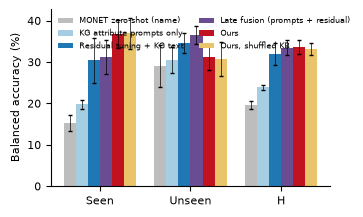

In [9]:
ms_ = [m for m in METHODS if m in set(Z['method'])]
cols_ = [('gzsl_s', 'Seen'), ('gzsl_u', 'Unseen'), ('gzsl_h', 'H')]; w = 0.8 / len(ms_)
fig, ax = plt.subplots(figsize=(3.6, 2.3))
for i, m in enumerate(ms_):
    g = Z[Z['method'] == m]
    ax.bar(np.arange(3) + (i - (len(ms_) - 1) / 2) * w, [g[c].mean() * 100 for c, _ in cols_], w,
           yerr=[g[c].std() * 100 for c, _ in cols_], color=PAL[m], label=NAMES[m], error_kw=dict(lw=0.5, capsize=1.5))
ax.set_xticks(range(3), [n for _, n in cols_]); ax.set_ylabel('Balanced accuracy (%)')
ax.legend(fontsize=5.5, frameon=False, ncol=2, loc='upper left')
savefig(fig, 'fig1_main_gzsl'); plt.show()

### Fig. 2 Seen-unseen trade-off curves (split 0)

saved figures_v2e\fig2_main_curves.pdf


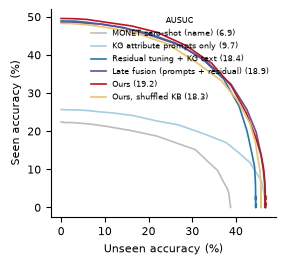

In [10]:
fig, ax = plt.subplots(figsize=(2.9, 2.7))
for m in [x for x in METHODS if x in set(Z['method'])]:
    r = Z[(Z['method'] == m) & (Z['split'] == 0)].iloc[0]; c = np.array(r['curve']) * 100
    ax.plot(c[:, 1], c[:, 0], c=PAL[m], lw=1.2, label=f"{NAMES[m]} ({r['ausuc'] * 100:.1f})")
ax.set_xlabel('Unseen accuracy (%)'); ax.set_ylabel('Seen accuracy (%)')
ax.legend(fontsize=5.5, frameon=False, title='AUSUC', title_fontsize=6)
savefig(fig, 'fig2_main_curves'); plt.show()

### Fig. 3 ZSL balanced accuracy with paired significance

saved figures_v2e\fig3_main_zsl.pdf


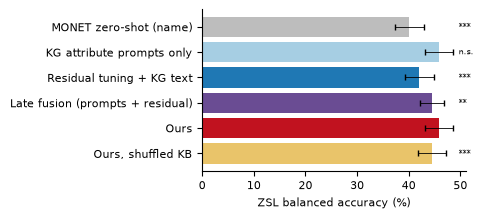

In [11]:
ms_ = [m for m in METHODS if m in set(Z['method'])]
v = Z.groupby('method')['zsl_bacc'].agg(['mean', 'std']).reindex(ms_) * 100
fig, ax = plt.subplots(figsize=(3.4, 2.1))
ax.barh(range(len(v)), v['mean'], xerr=v['std'], color=[PAL[m] for m in ms_], error_kw=dict(lw=0.6, capsize=2))
for i, m in enumerate(ms_):
    if m != 'ours':
        p = paired('ours', m, 'zsl_bacc')['p']
        ax.text(v['mean'].max() + v['std'].max() + 1, i, '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.',
                va='center', fontsize=6)
ax.set_yticks(range(len(v)), [NAMES[m] for m in ms_]); ax.invert_yaxis(); ax.set_xlabel('ZSL balanced accuracy (%)')
savefig(fig, 'fig3_main_zsl'); plt.show()

### Fig. 4 Per-split gains of ours over residual tuning + KG text

saved figures_v2e\fig4_gain_per_split.pdf


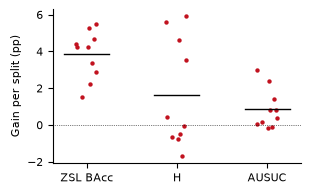

In [12]:
A = Z[Z['method'] == 'ours'].set_index('split'); B = Z[Z['method'] == 'residual_kgtext'].set_index('split').reindex(A.index)
fig, ax = plt.subplots(figsize=(3.2, 2.0))
for j, (c, lab) in enumerate([('zsl_bacc', 'ZSL BAcc'), ('gzsl_h', 'H'), ('ausuc', 'AUSUC')]):
    d = (A[c] - B[c]) * 100
    ax.scatter(np.full(len(d), j) + np.random.default_rng(0).uniform(-0.12, 0.12, len(d)), d, s=10, c='#c1121f', lw=0)
    ax.plot([j - 0.25, j + 0.25], [d.mean()] * 2, c='k', lw=1)
ax.axhline(0, c='k', lw=0.5, ls=':'); ax.set_xticks(range(3), ['ZSL BAcc', 'H', 'AUSUC'])
ax.set_ylabel('Gain per split (pp)')
savefig(fig, 'fig4_gain_per_split'); plt.show()

In [1]:
print(open('results_v2c/paired_tests.csv').read())
print(open('results_v2e/paired_tests.csv').read())

comparison,metric,diff,paired_std,wins,p
Ours vs MONET zero-shot (name),zsl_bacc,5.73,2.15,10/10,0.0
Ours vs MONET zero-shot (KG text),zsl_bacc,3.85,1.37,10/10,0.0
Ours vs Description mean (no KG structure),zsl_bacc,2.29,1.21,10/10,0.0002
"Ours vs KG types, equal weights",zsl_bacc,1.43,0.81,9/10,0.0003
"Ours vs Ours, shuffled KB",zsl_bacc,1.33,0.82,10/10,0.0006
Ours vs MONET zero-shot (name),gzsl_h,3.99,0.75,10/10,0.0
Ours vs MONET zero-shot (KG text),gzsl_h,2.83,0.77,10/10,0.0
Ours vs Description mean (no KG structure),gzsl_h,1.25,0.52,10/10,0.0
"Ours vs KG types, equal weights",gzsl_h,0.67,0.76,8/10,0.0222
"Ours vs Ours, shuffled KB",gzsl_h,0.85,0.41,10/10,0.0001
MONET zero-shot (KG text) vs MONET zero-shot (name),zsl_bacc,1.88,2.88,7/10,0.0691

comparison,metric,diff,paired_std,wins,p
Ours vs MONET zero-shot (name),zsl_bacc,5.73,2.15,10/10,0.0
Ours vs KG attribute prompts only,zsl_bacc,0.0,0.0,0/10,
Ours vs Residual tuning + KG text,zsl_bacc,3.84,1.3,10/10,0.0
Ours vs Late fusion (p